<a href="https://colab.research.google.com/github/LucaBaronee/FinalLab3/blob/main/Copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_raw = pd.read_csv(url)   # original: no se modifica
df = df_raw.copy()          # copia de trabajo


Sirve para contar filas y columnas


In [5]:
df.shape


(891, 12)

Sirve para informacion de datos
Que observamos aca?
Observamos que en total de 891 en total, en edad faltan 177, y en cabin faltarian 687 datos.


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Que hay que ver aca? Cuantos sobrevivieron?
MEAN SURVIVED = 0.38 = 38%
Clase mas comun? Pclass Media = 3.00 (50%)
Edades correctas? No hay valores negativos ni muy grandes. Media y mediana muy parecidas.
Precio de ticket (FARE) PROMEDIO 32.20, MEDIANA 14.45. Max 512.32



Te tira la
 cantidad de nulos.


In [8]:
df.isna().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Te tira el porcentaje de nulos


In [9]:
(df.isna().mean() * 100).round(1)


,0
PassengerId,0.0
Survived,0.0
Pclass,0.0
Name,0.0
Sex,0.0
Age,19.9
SibSp,0.0
Parch,0.0
Ticket,0.0
Fare,0.0


Cantadad de filas repetidas


In [10]:
df.duplicated().sum()


np.int64(0)

df = df.drop_duplicates() para filas repetidas



In [11]:
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


PASAMOS CLASES QUE ESTABAN COMO INT PERO QUE NO LO SON

In [12]:
df["Survived"] = df["Survived"].astype("category")
df["Pclass"] = df["Pclass"].astype("category")

In [13]:
df.dtypes


,0
PassengerId,int64
Survived,category
Pclass,category
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


Pone a todo en minusculas para que tome el mismo valor
df["Sex"] selecciona la columna.
.str le dice a Pandas que aplique funciones de texto a cada valor.
.strip() elimina espacios al principio y al final (" male " pasa a "male").
.lower() pasa todo a minúsculas ("Male" pasa a "male").
df["Sex"] = ... guarda el resultado en la misma columna.

In [14]:
df["Sex"] = df["Sex"].str.strip().str.lower()

In [15]:
df["Embarked"] = df["Embarked"].str.strip().str.upper()


In [16]:
df["Embarked"].unique()


array(['S', 'C', 'Q', nan], dtype=object)

Mira si hay edades negativas  y ahora controlar todos los datos



In [17]:
(df["Age"] < 0).sum()


np.int64(0)

In [18]:
(df["Fare"] < 0).sum()


np.int64(0)

Quienes les salio gratis? Es raro? Porque sera? Es importante el dato?

In [19]:
(df["Fare"] == 0).sum()

np.int64(15)

Valores MINIMOS Y MAXIMOS

In [20]:
df["Age"].min(), df["Age"].max()


(0.42, 80.0)

Empezemos a fijarse en los nulos,traemos a los 2 nulos de embarkados




In [21]:
df[df["Embarked"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


Como es una variable categorica, y solo faltan dos se calcula con la MODA (El que mas aparece) con 644 de casos


In [22]:
df["Embarked"].mode()[0]


'S'

Agarra a los nulos y lo llena de la moda, ahora hay 0 nulos

In [23]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Embarked"].isna().sum()

np.int64(0)

In [24]:
df["Age"].isna().sum()


np.int64(177)

Por qué la mediana y no la media: Age tiene algunos valores altos (mayores de ~65), y la media se ve afectada por los valores extremos. La mediana no, así que es una opción más segura para rellenar.


In [25]:
df["Age"].median()


28.0

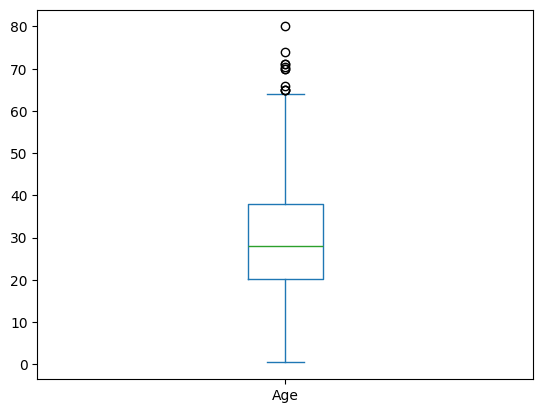

In [26]:
df["Age"].plot(kind="box")
plt.show()


Los puntos que aparecen por fuera de los bigotes son los valores atípicos. En Age vas a ver unos pocos puntos arriba, cerca de los 65-80 años.

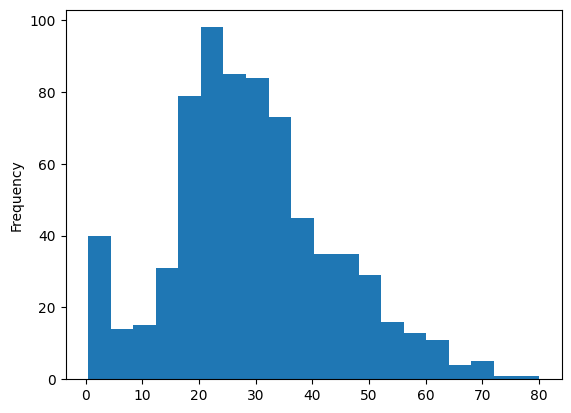

In [27]:
df["Age"].plot(kind="hist", bins=20)
plt.show()


Muestra la forma de la distribución. Si tiene una “cola” larga hacia la derecha, hay valores altos que desplazan la media.

df["Age"].median() calcula la mediana (28.0), ignorando los nulos.
.fillna(...) reemplaza cada NaN de la columna por ese valor.
df["Age"] = ... guarda el resultado en la misma columna.

In [28]:
df["Age"] = df["Age"].fillna(df["Age"].median())

IMPORTANTE VERIFICAR

In [29]:
df["Age"].isna().sum()

np.int64(0)

In [30]:
df["Age"].describe()

,Age
count,891.000000
mean,29.361582
std,13.019697
min,0.420000
25%,22.000000
50%,28.000000
75%,35.000000
max,80.000000


La conclusión

Imputar con un único valor no cambia el centro, pero sí achica la dispersión artificialmente. Los datos reales no se volvieron más parecidos entre sí: es un efecto de haber rellenado con el mismo número. Por eso se menciona como limitación en el informe.

In [31]:
df["Cabin"].notna().sum(), df["Cabin"].isna().sum()

(np.int64(204), np.int64(687))

In [32]:
df["TieneCabina"] = df["Cabin"].notna().astype(int)

In [33]:
df["TieneCabina"].value_counts()

,count
TieneCabina,
0,687
1,204


In [34]:
pd.crosstab(df["Pclass"], df["TieneCabina"])

TieneCabina,0,1
Pclass,,
1,40,176
2,168,16
3,479,12


In [35]:
df = df.drop(columns="Cabin")

“Cabin tenía 687 nulos (77,1%). No se imputó porque no existe un valor razonable para rellenar y se habría inventado la mayor parte de la columna. En su lugar se creó TieneCabina (1 = registrada, 0 = no), ya que la ausencia del dato se asocia con la clase del pasajero. Luego se eliminó Cabin.”
“La tabla de contingencia muestra que el registro de cabina depende fuertemente de la clase: en 1ª clase el ~81% tiene cabina registrada, frente a ~2% en 3ª. Esto confirma que la ausencia del dato es informativa y justifica haber creado TieneCabina.

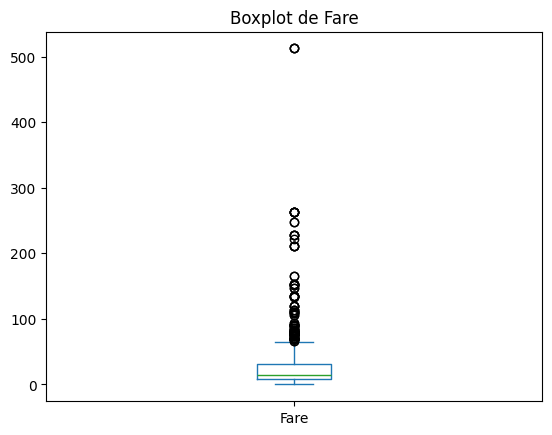

In [37]:
df["Fare"].plot(kind="box")
plt.title("Boxplot de Fare")
plt.show()

La caja va de Q1 a Q3, o sea el 50% central de los datos.
La línea dentro de la caja es la mediana.
Los bigotes llegan hasta 1,5 veces el rango intercuartílico.
Los puntos sueltos fuera de los bigotes son los valores atípicos.

Celda 2: calcular los límites con la regla del IQR

In [38]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

Q1, Q3, IQR, lim_inf, lim_sup

(np.float64(7.9104),
 np.float64(31.0),
 np.float64(23.0896),
 np.float64(-26.724),
 np.float64(65.6344))

Qué hace cada línea:

.quantile(0.25) y .quantile(0.75) devuelven Q1 y Q3 (los mismos que viste en describe(): 7,91 y 31,0).
IQR = Q3 - Q1 es el rango intercuartílico, la amplitud del 50% central (~23,1).
Los límites se calculan a 1,5 IQR de cada cuartil. Todo lo que quede afuera se considera atípico.

Te va a dar un límite superior de ~65,6 y un límite inferior negativo (que en la práctica no aplica, porque no hay tarifas menores a 0).

In [39]:
outliers = df[(df["Fare"] < lim_inf) | (df["Fare"] > lim_sup)]
outliers.shape[0]

116

Cuenta los outliers

In [40]:
outliers[["Pclass", "Fare", "Survived"]].head(10)

,Pclass,Fare,Survived
1,1,71.2833,1
27,1,263.0000,0
31,1,146.5208,1
34,1,82.1708,0
52,1,76.7292,1
61,1,80.0000,1
62,1,83.4750,0
72,2,73.5000,0
88,1,263.0000,1
102,1,77.2875,0


In [41]:
outliers["Pclass"].value_counts()


,count
Pclass,
1,104
3,7
2,5


In [42]:
df.groupby("Pclass", observed=True)["Fare"].agg(["mean", "median", "count"])

,mean,median,count
Pclass,,,
1,84.154687,60.2875,216
2,20.662183,14.2500,184
3,13.675550,8.0500,491
